# Exercise 2
Nico Reiterer - 5191 2112

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2.1. c)
Write a matlab or python program that computes the Newton coefficients and evaluates the
resulting polynomial at a vector of evaluation points using the Horner scheme. Input are the
vectors x, f (knots and data values) of length n+ 1.
Check your routines against the results of a) and b). Plot f and p3 on [0,4], and calculate the
error $||f−p3||{_∞,[0,4]}.$ by sampling using 1001 uniformly distributed evaluation points.

In [20]:
def newton_polynomial(j: int, x: np.ndarray, x_dash: float | np.ndarray) -> float | np.ndarray:
    """
        j: order of the polynomial
        x: knots x_i
        x_dash: evaluation point

        Returns:
            The newton polynomial w_j
    """

    x_dash = np.asarray(x_dash, dtype=float)
    return np.prod(x_dash[..., None] - x[:j], axis=-1)


def divided_differences(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """
        x: knots x_i
        y: values f(x_i)

        Returns:
            Newton coefficients c_j = f[x_0, ..., x_j]
    
    """
    # start of the row k = 0
    c = np.array(y, dtype=float)

    # k elem of [0, n-1] based on the number of knots.
    n = len(x) 
    # Essentially going along the columns and creating in first step f[x0, x1], f[x1, x2] ...
    # Then in next step taking these calculated ones to create f[x0, x1, x2] consisting for the
    # created f[x0, x1], f[x1, x2] >> f[x0, x1, x2] =  f[x1, x2] - f[x0, x1] / x2-x1
    for k in range(1, n):
        for i in range(n - 1, k - 1, -1):   # go backwards so c[i-1] is still the old value
            c[i] = (c[i] - c[i-1]) / (x[i] - x[i-k])
    return c


def horner_schema(c: np.ndarray, x: np.ndarray, x_dash: float | np.ndarray) -> float | np.ndarray:
    """
        c: Newton coefficients (from divided_differences)
        x: knots x_i
        x_dash: evaluation point(s), scalar or array

        Returns:
            p(x_dash) evaluated with the Horner-like scheme
    """
    x_dash = np.asarray(x_dash, dtype=float)
    y = np.full_like(x_dash, c[-1]) # just to be flexible for evaluation of multiple x_dashes at once
    for j in range(len(c) - 2, -1, -1):
        y = y * (x_dash - x[j]) + c[j]
    return y


Newton coefficients: [ 1.         -0.5         0.16666667 -0.03333333]
|f(3) - p3(3)| = 0.050000000000000044
||f - p3||_inf,[0,4] = 0.053771  (attained at x ≈ 3.244)


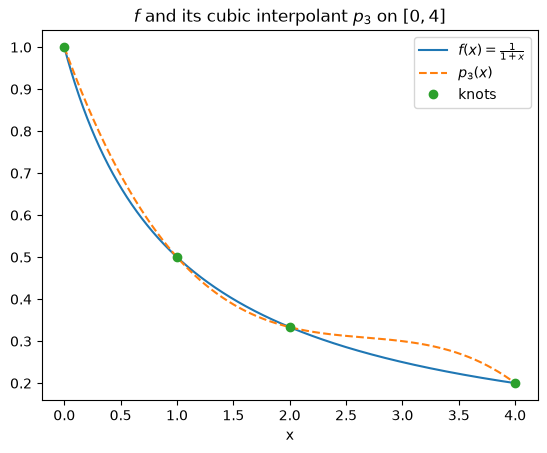

In [33]:
# Validating my results from the handwritten evaluation
x = np.array([0., 1, 2, 4])
f = lambda x: 1/(1+x)
c = divided_differences(x, f(x))

# a): c = [f[x0], f[x0,x1], f[x0,x1,x2], f[x0,...,x3]] = [1, -1/2, 1/6, -1/30]
print("Newton coefficients:", c)

# b): p3(3) = 0.3, |f(3) - p3(3)| = 0.05
print("|f(3) - p3(3)| =", abs(f(3) - horner_schema(c, x, 3)))

# Now the uniformly distributed values between 0 and 4
x_eval = np.linspace(0, 4, 1001)
f_eval = f(x_eval)
p3_eval = horner_schema(c, x, x_eval)

error = np.abs(f_eval - p3_eval)
print(f"||f - p3||_inf,[0,4] = {error.max():.6f}  (attained at x ≈ {x_eval[error.argmax()]:.3f})")

plt.plot(x_eval, f_eval, label=r"$f(x) = \frac{1}{1+x}$")
plt.plot(x_eval, p3_eval, "--", label=r"$p_3(x)$")
plt.plot(x, f(x), "o", label="knots")
plt.xlabel("x")
plt.legend()
plt.title(r"$f$ and its cubic interpolant $p_3$ on $[0, 4]$")
plt.show()